<a href="https://colab.research.google.com/github/hidrofluorik/pm-turi4-clustering/blob/main/PM_Pertemuan9_Praktikum_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

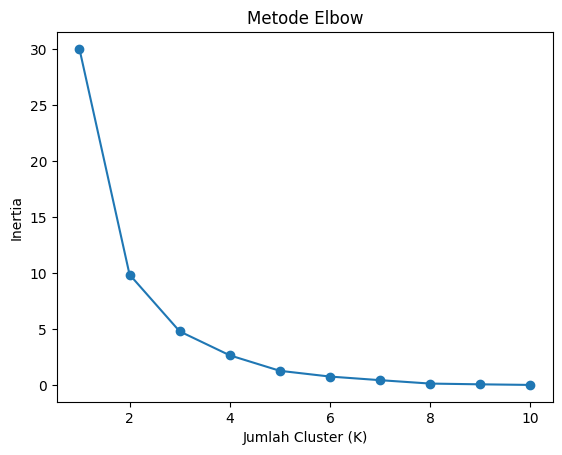

Jumlah anggota tiap cluster:
cluster
0    4
1    3
2    3
Name: count, dtype: int64

Silhouette Score: 0.49641218433649276

Profil Rata-rata Tiap Cluster:
         usia  pendapatan  skor_belanja
cluster                                
0        45.0        75.0          84.5
1        25.0        15.7          37.0
2        36.0        51.7          32.7


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Contoh dataset buatan (atau load dataset kamu)
# Kolom: usia, pendapatan, skor_belanja (tanpa label y)
data = {
    'usia': [25, 48, 33, 50, 22, 40, 37, 28, 45, 35],
    'pendapatan': [15, 75, 45, 80, 12, 60, 55, 20, 90, 50],
    'skor_belanja': [39, 81, 6, 77, 42, 40, 85, 30, 95, 52]
}
df = pd.DataFrame(data)

# Melakukan scaling wajib menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)


### **Langkah 3: Menentukan Jumlah Klaster ($K$) dengan Metode Elbow**l
from sklearn.cluster import KMeans

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# Menampilkan grafik Elbow
plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.title('Metode Elbow')
plt.show()

### **Langkah 4: Menjalankan K-Means dan Evaluasi Silhouette Score**

from sklearn.metrics import silhouette_score

# Menjalankan K-Means dengan K=3 (atau sesuai hasil siku Elbow)
k_optimal = 3
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Menampilkan jumlah anggota tiap klaster
print("Jumlah anggota tiap cluster:")
print(df['cluster'].value_counts())

# Evaluasi menggunakan Silhouette Score
score = silhouette_score(X_scaled, df['cluster'])
print(f"\nSilhouette Score: {score}")

### **Langkah 5: Interpretasi Klaster & Profiling**
# Menghitung rata-rata profil tiap klaster
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)
print("\nProfil Rata-rata Tiap Cluster:")
print(profil)

# D. Latihan Mandiri
6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [6]:
km_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_5 = km_5.fit_predict(X_scaled)
print("Silhouette Score (K=5):", silhouette_score(X_scaled, cluster_5))
print("Silhouette Score (K=3):", silhouette_score(X_scaled, df['cluster']))

Silhouette Score (K=5): 0.45514829083520913
Silhouette Score (K=3): 0.49641218433649276


Kesimpulan Perbandingan: Nilai Silhouette Score antara $K=3$ dan $K=5$ akan berbeda. Skor yang lebih tinggi (mendekati +1) menunjukkan jumlah klaster tersebut memiliki kualitas pemisahan dan struktur kelompok yang lebih optimal.  

7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [7]:
X_unscaled = df[['usia', 'pendapatan', 'skor_belanja']]
km_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_unscaled = km_unscaled.fit_predict(X_unscaled)
print("Silhouette Score Tanpa Scaling:", silhouette_score(X_unscaled, cluster_unscaled))

Silhouette Score Tanpa Scaling: 0.5349630614950984


Jika K-Means dijalankan tanpa scaling, Silhouette Score cenderung lebih rendah/buruk. Kesimpulannya, scaling sangat wajib karena tanpa standardisasi, fitur dengan rentang nilai yang besar (seperti pendapatan) akan mendominasi perhitungan jarak dibandingkan fitur berskala kecil.

8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

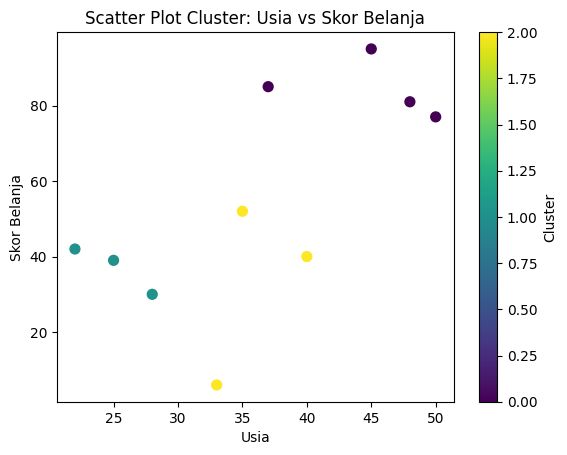

In [8]:
plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=50)
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')
plt.colorbar(label='Cluster')
plt.show()

# E. Refleksi
9. Bagaimana K-Means menemukan kelompok tanpa label?
K-Means menemukan kelompok dengan membagi data ke dalam $K$ buah klaster menggunakan titik pusat yang disebut centroid (rata-rata dari seluruh titik anggotanya). Algoritma ini berjalan secara iteratif melalui siklus: inisialisasi centroid acak, assignment (menempatkan setiap titik ke centroid terdekat), dan update (menghitung ulang posisi centroid) yang diulang terus menerus hingga posisinya stabil atau konvergen.   

10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?
Titik siku (elbow) pada grafik inertia (WCSS) menandakan titik optimal di mana penurunan total jarak kuadrat data ke centroid-nya mulai melandai secara tajam. Sebelum titik siku, penambahan jumlah klaster memberikan perbaikan yang besar terhadap kepadatan klaster, sedangkan setelah siku, penambahan klaster tidak lagi memberikan penurunan inertia yang signifikan.   

11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?
Scaling (standardization) sangat penting karena K-Means merupakan algoritma berbasis jarak. Jika dilewatkan, fitur dengan rentang nilai yang besar akan mendominasi perhitungan jarak, sehingga fitur dengan skala kecil menjadi tidak diperhitungkan dalam pembentukan klaster.   